# CART Classification Using the PlayTennis Dataset

**Machine Learning Assignment**

**Objective:** Implement CART (Classification and Regression Trees) using the classic PlayTennis dataset. Since `PlayTennis` contains two classes (`Yes` and `No`), this is a **classification** problem.

### Notebook roadmap
1. Explore the data and understand Gini impurity.
2. Find the best binary split.
3. Build CART recursively from scratch.
4. Apply pre-pruning and cost-complexity post-pruning.
5. Evaluate using Leave-One-Out Cross-Validation (LOOCV).
6. Compare with scikit-learn.

The explanations use simple language, and the code is organized step by step.

## 1. Import libraries

Pandas manages the dataset, NumPy supports calculations, Matplotlib draws the tree, and scikit-learn provides evaluation tools and a reference model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline

RANDOM_STATE = 42

## 2. Create and inspect the PlayTennis dataset

The dataset has 14 weather observations. The four weather columns are input features, and `PlayTennis` is the target we want to predict.

In [2]:
data = pd.DataFrame({
    "Outlook": ["Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain",
                "Overcast", "Sunny", "Sunny", "Rain", "Sunny",
                "Overcast", "Overcast", "Rain"],
    "Temperature": ["Hot", "Hot", "Hot", "Mild", "Cool", "Cool",
                    "Cool", "Mild", "Cool", "Mild", "Mild",
                    "Mild", "Hot", "Mild"],
    "Humidity": ["High", "High", "High", "High", "Normal", "Normal",
                 "Normal", "High", "Normal", "Normal", "Normal",
                 "High", "Normal", "High"],
    "Wind": ["Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
             "Strong", "Weak", "Weak", "Weak", "Strong",
             "Strong", "Weak", "Strong"],
    "PlayTennis": ["No", "No", "Yes", "Yes", "Yes", "No", "Yes",
                   "No", "Yes", "Yes", "Yes", "Yes", "Yes", "No"]
})

FEATURES = ["Outlook", "Temperature", "Humidity", "Wind"]
TARGET = "PlayTennis"
X = data[FEATURES].copy()
y = data[TARGET].copy()

display(data)
print("Records:", len(data))
display(y.value_counts().to_frame("Class count"))

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


Records: 14


,Class count
PlayTennis,
Yes,9
No,5


## 3. Gini impurity

Gini impurity measures how mixed the classes are in a group.

\[
Gini = 1 - \sum p_k^2
\]

Here, \(p_k\) is the proportion of each class. A Gini value of `0` means the group is completely pure. CART selects the split with the lowest weighted child Gini (highest Gini reduction).

In [3]:
def gini(labels):
    """Calculate Gini impurity for a group of class labels."""
    labels = pd.Series(labels)
    if len(labels) == 0:
        return 0.0
    probabilities = labels.value_counts(normalize=True)
    return float(1 - (probabilities ** 2).sum())


parent_gini = gini(y)
print(f"Parent Gini impurity: {parent_gini:.4f}")

Parent Gini impurity: 0.4592


## 4. Generate unique binary splits

CART divides each node into two groups. For example, `Outlook` can be split into `{Sunny}` and `{Rain, Overcast}`. Mirror duplicates are removed.

In [4]:
def binary_partitions(values):
    """Return unique non-empty binary partitions of categorical values."""
    values = sorted(pd.Series(values).dropna().unique().tolist())
    if len(values) < 2:
        return []

    first, remaining = values[0], values[1:]
    result = []
    for size in range(len(remaining) + 1):
        for group in combinations(remaining, size):
            left = frozenset((first, *group))
            right = frozenset(values) - left
            if right:
                result.append((left, right))
    return result


def best_split(X_part, y_part, features):
    """Find the split with the largest reduction in Gini impurity."""
    best = None
    parent = gini(y_part)
    n = len(y_part)

    for feature in features:
        for left_values, right_values in binary_partitions(X_part[feature]):
            left_mask = X_part[feature].isin(left_values)
            right_mask = ~left_mask
            if left_mask.sum() == 0 or right_mask.sum() == 0:
                continue

            left_gini = gini(y_part[left_mask])
            right_gini = gini(y_part[right_mask])
            weighted = (left_mask.sum() / n * left_gini
                        + right_mask.sum() / n * right_gini)
            gain = parent - weighted

            candidate = {
                "feature": feature, "left_values": left_values,
                "left_mask": left_mask, "right_mask": right_mask,
                "left_gini": left_gini, "right_gini": right_gini,
                "weighted_gini": weighted, "gain": gain
            }
            if best is None or gain > best["gain"] + 1e-12:
                best = candidate
    return best


root = best_split(X, y, FEATURES)
print("Best root feature:", root["feature"])
print("Left group:", sorted(root["left_values"]))
print(f"Weighted child Gini: {root['weighted_gini']:.4f}")
print(f"Gini reduction: {root['gain']:.4f}")

Best root feature: Outlook
Left group: ['Overcast']
Weighted child Gini: 0.3571
Gini reduction: 0.1020


## 5. Implement CART from scratch

The tree is built recursively. At each node, the algorithm finds the best split, creates two child groups, and repeats the process. It stops when a node is pure or a pre-pruning limit is reached.

In [5]:
def majority_class(labels):
    counts = pd.Series(labels).value_counts()
    return sorted(counts[counts == counts.max()].index)[0]


def build_cart(X_part, y_part, features, depth=0,
               max_depth=None, min_samples_leaf=1, min_gain=1e-12):
    """Build a binary CART classification tree."""
    node = {
        "prediction": majority_class(y_part),
        "samples": len(y_part),
        "gini": gini(y_part),
        "feature": None,
        "left_values": None,
        "left": None,
        "right": None,
        "depth": depth
    }

    if node["gini"] == 0 or len(y_part) < 2 * min_samples_leaf:
        return node
    if max_depth is not None and depth >= max_depth:
        return node

    split = best_split(X_part, y_part, features)
    if split is None or split["gain"] <= min_gain:
        return node

    left_mask, right_mask = split["left_mask"], split["right_mask"]
    if min(left_mask.sum(), right_mask.sum()) < min_samples_leaf:
        return node

    node.update({
        "feature": split["feature"],
        "left_values": split["left_values"],
        "gain": split["gain"],
        "left": build_cart(X_part.loc[left_mask], y_part.loc[left_mask],
                           features, depth + 1, max_depth,
                           min_samples_leaf, min_gain),
        "right": build_cart(X_part.loc[right_mask], y_part.loc[right_mask],
                            features, depth + 1, max_depth,
                            min_samples_leaf, min_gain)
    })
    return node


def predict_one(node, row):
    """Follow the decision rules to predict one observation."""
    while node["feature"] is not None:
        if row[node["feature"]] in node["left_values"]:
            node = node["left"]
        else:
            node = node["right"]
    return node["prediction"]


def predict_cart(tree, X_new):
    return np.array([predict_one(tree, row) for _, row in X_new.iterrows()])


def tree_depth(node):
    if node["feature"] is None:
        return 0
    return 1 + max(tree_depth(node["left"]), tree_depth(node["right"]))


def leaf_count(node):
    if node["feature"] is None:
        return 1
    return leaf_count(node["left"]) + leaf_count(node["right"])

## 6. Train the full CART tree

The full tree grows until its leaves are pure or no useful split remains. Training accuracy measures fit on known data; it is not a reliable estimate of performance on new data.

In [6]:
full_tree = build_cart(X, y, FEATURES)
print("Training accuracy:",
      f"{accuracy_score(y, predict_cart(full_tree, X)):.2%}")
print("Tree depth:", tree_depth(full_tree))
print("Number of leaves:", leaf_count(full_tree))

Training accuracy: 100.00%
Tree depth: 4
Number of leaves: 7


## 7. Read the decision rules

Each internal node asks a question about one feature. The left branch contains the listed category values; the right branch contains the remaining values.

In [7]:
def show_rules(node, indent=""):
    if node["feature"] is None:
        print(f"{indent}Predict {node['prediction']} "
              f"(records={node['samples']}, Gini={node['gini']:.3f})")
        return

    values = ", ".join(sorted(node["left_values"]))
    print(f"{indent}If {node['feature']} is in {{{values}}}:")
    show_rules(node["left"], indent + "  ")
    print(f"{indent}Otherwise:")
    show_rules(node["right"], indent + "  ")


show_rules(full_tree)

If Outlook is in {Overcast}:
  Predict Yes (records=4, Gini=0.000)
Otherwise:
  If Humidity is in {High}:
    If Outlook is in {Rain}:
      If Wind is in {Strong}:
        Predict No (records=1, Gini=0.000)
      Otherwise:
        Predict Yes (records=1, Gini=0.000)
    Otherwise:
      Predict No (records=3, Gini=0.000)
  Otherwise:
    If Wind is in {Strong}:
      If Outlook is in {Rain}:
        Predict No (records=1, Gini=0.000)
      Otherwise:
        Predict Yes (records=1, Gini=0.000)
    Otherwise:
      Predict Yes (records=3, Gini=0.000)


## 8. Pre-pruning

Pre-pruning limits tree growth during training. Here, the maximum depth is 2 and each leaf must contain at least 2 records.

In [8]:
pre_pruned_tree = build_cart(
    X, y, FEATURES, max_depth=2, min_samples_leaf=2
)

print("Depth:", tree_depth(pre_pruned_tree))
print("Leaves:", leaf_count(pre_pruned_tree))
print("Training accuracy:",
      f"{accuracy_score(y, predict_cart(pre_pruned_tree, X)):.2%}")

Depth: 2
Leaves: 3
Training accuracy: 85.71%


## 9. Post-pruning with cost complexity

Post-pruning first grows a full tree and then removes branches that do not justify their complexity. The `alpha` parameter controls the penalty for extra leaves.

In [9]:
def prune_cart(node, alpha=0.01, root_samples=None):
    """Prune branches when a single leaf has lower penalized risk."""
    if root_samples is None:
        root_samples = node["samples"]
    if node["feature"] is None:
        return node

    node["left"] = prune_cart(node["left"], alpha, root_samples)
    node["right"] = prune_cart(node["right"], alpha, root_samples)

    leaf_risk = node["samples"] / root_samples * node["gini"]

    def subtree_stats(current):
        if current["feature"] is None:
            risk = current["samples"] / root_samples * current["gini"]
            return risk, 1
        lr, ll = subtree_stats(current["left"])
        rr, rl = subtree_stats(current["right"])
        return lr + rr, ll + rl

    subtree_risk, leaves = subtree_stats(node)
    if leaf_risk <= subtree_risk + alpha * (leaves - 1):
        node["feature"] = None
        node["left_values"] = None
        node["left"] = None
        node["right"] = None
        node.pop("gain", None)
    return node


post_pruned_tree = prune_cart(build_cart(X, y, FEATURES), alpha=0.01)
print("Depth:", tree_depth(post_pruned_tree))
print("Leaves:", leaf_count(post_pruned_tree))
print("Training accuracy:",
      f"{accuracy_score(y, predict_cart(post_pruned_tree, X)):.2%}")

Depth: 4
Leaves: 7
Training accuracy: 100.00%


## 10. Compare full, pre-pruned and post-pruned trees

Training accuracy shows fit on the training records. Depth and leaf count show how complex each tree is. Cross-validation in the next section gives a better estimate for unseen records.

In [10]:
models = {
    "Full CART": full_tree,
    "Pre-pruned CART": pre_pruned_tree,
    "Post-pruned CART": post_pruned_tree
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "Training accuracy": accuracy_score(y, predict_cart(model, X)),
        "Depth": tree_depth(model),
        "Leaves": leaf_count(model)
    }
    for name, model in models.items()
])
display(comparison.round(3))

,Model,Training accuracy,Depth,Leaves
0,Full CART,1.000,4,7
1,Pre-pruned CART,0.857,2,3
2,Post-pruned CART,1.000,4,7


## 11. Visualize the manual CART tree

The diagram shows the questions and the predicted class at each leaf.

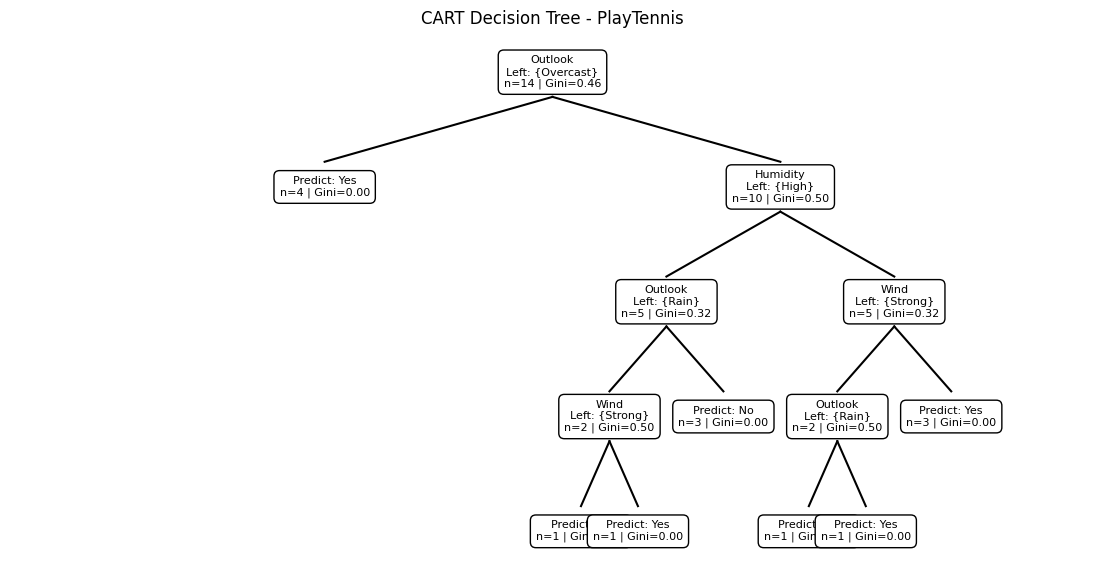

In [11]:
def draw_tree(node, ax, x=0.5, y_pos=1.0, width=0.42):
    if node["feature"] is None:
        label = (f"Predict: {node['prediction']}\n"
                 f"n={node['samples']} | Gini={node['gini']:.2f}")
    else:
        values = ", ".join(sorted(node["left_values"]))
        label = (f"{node['feature']}\nLeft: {{{values}}}\n"
                 f"n={node['samples']} | Gini={node['gini']:.2f}")

    ax.text(x, y_pos, label, ha="center", va="center", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="black"))

    if node["feature"] is not None:
        child_y = y_pos - 0.23
        left_x, right_x = x - width / 2, x + width / 2
        ax.plot([x, left_x], [y_pos - 0.05, child_y + 0.05], "k-")
        ax.plot([x, right_x], [y_pos - 0.05, child_y + 0.05], "k-")
        draw_tree(node["left"], ax, left_x, child_y, width / 2)
        draw_tree(node["right"], ax, right_x, child_y, width / 2)


fig, ax = plt.subplots(figsize=(14, 7))
ax.set_title("CART Decision Tree - PlayTennis")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.08)
ax.axis("off")
draw_tree(full_tree, ax)
plt.show()

## 12. Evaluate with Leave-One-Out Cross-Validation

There are only 14 observations. LOOCV trains the model 14 times, each time holding out one record for testing and training on the other 13. This is more informative than training accuracy, although results can still vary on such a small dataset.

In [12]:
loo = LeaveOneOut()

def manual_loo_predictions(X_data, y_data, max_depth=None,
                           min_samples_leaf=1, alpha=None):
    predictions = []
    for train_idx, test_idx in loo.split(X_data):
        X_train = X_data.iloc[train_idx]
        X_test = X_data.iloc[test_idx]
        y_train = y_data.iloc[train_idx]

        tree = build_cart(
            X_train, y_train, FEATURES,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf
        )
        if alpha is not None:
            tree = prune_cart(tree, alpha=alpha)
        predictions.append(predict_cart(tree, X_test)[0])

    return np.array(predictions)


loo_predictions = {
    "Full CART": manual_loo_predictions(X, y),
    "Pre-pruned CART": manual_loo_predictions(
        X, y, max_depth=2, min_samples_leaf=2
    ),
    "Post-pruned CART": manual_loo_predictions(X, y, alpha=0.01)
}

loo_results = pd.DataFrame([
    {"Model": name, "LOOCV accuracy": accuracy_score(y, pred)}
    for name, pred in loo_predictions.items()
])
display(loo_results.round(3))

,Model,LOOCV accuracy
0,Full CART,0.500
1,Pre-pruned CART,0.643
2,Post-pruned CART,0.500


## 13. Confusion matrix and classification report

The confusion matrix shows the correct and incorrect predictions for each class. Precision, recall and F1-score provide additional information beyond accuracy.

In [13]:
for name, predictions in loo_predictions.items():
    print("\n", name)
    print("Confusion matrix (actual rows, predicted columns; No, Yes):")
    print(confusion_matrix(y, predictions, labels=["No", "Yes"]))
    print(classification_report(
        y, predictions, labels=["No", "Yes"], zero_division=0
    ))


 Full CART
Confusion matrix (actual rows, predicted columns; No, Yes):
[[2 3]
 [4 5]]
              precision    recall  f1-score   support

          No       0.33      0.40      0.36         5
         Yes       0.62      0.56      0.59         9

    accuracy                           0.50        14
   macro avg       0.48      0.48      0.48        14
weighted avg       0.52      0.50      0.51        14


 Pre-pruned CART
Confusion matrix (actual rows, predicted columns; No, Yes):
[[2 3]
 [2 7]]
              precision    recall  f1-score   support

          No       0.50      0.40      0.44         5
         Yes       0.70      0.78      0.74         9

    accuracy                           0.64        14
   macro avg       0.60      0.59      0.59        14
weighted avg       0.63      0.64      0.63        14


 Post-pruned CART
Confusion matrix (actual rows, predicted columns; No, Yes):
[[2 3]
 [4 5]]
              precision    recall  f1-score   support

          No     

## 14. Compare with scikit-learn CART

This reference model uses scikit-learn's `DecisionTreeClassifier` with the Gini criterion. One-hot encoding converts the categories into numeric columns. The manual recursive implementation above remains the main assignment implementation.

In [14]:
sklearn_cart = make_pipeline(
    OneHotEncoder(handle_unknown="ignore"),
    DecisionTreeClassifier(criterion="gini", random_state=RANDOM_STATE)
)

sklearn_predictions = cross_val_predict(
    sklearn_cart, X, y, cv=LeaveOneOut()
)

reference = pd.DataFrame([{
    "Model": "scikit-learn CART",
    "LOOCV accuracy": accuracy_score(y, sklearn_predictions)
}])

all_results = pd.concat([loo_results, reference], ignore_index=True)
display(all_results.sort_values("LOOCV accuracy", ascending=False).round(3))

,Model,LOOCV accuracy
1,Pre-pruned CART,0.643
3,scikit-learn CART,0.643
0,Full CART,0.500
2,Post-pruned CART,0.500


## 15. Predict a new weather situation

The trained full tree predicts whether tennis can be played for this example weather condition.

In [15]:
new_day = pd.DataFrame([{
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Strong"
}])

print("New weather situation:")
display(new_day)
print("Predicted PlayTennis:", predict_cart(full_tree, new_day)[0])

New weather situation:


,Outlook,Temperature,Humidity,Wind
0,Sunny,Cool,High,Strong


Predicted PlayTennis: No


## 16. Conclusion

In this assignment, we implemented **CART classification from scratch** using the PlayTennis dataset.

- Gini impurity was used to measure class mixing.
- The best binary split was selected using Gini reduction.
- A recursive function built the decision tree.
- Pre-pruning limited tree growth, and cost-complexity post-pruning removed branches.
- LOOCV, confusion matrices and classification metrics were used for evaluation.
- The manual implementation was compared with scikit-learn CART.

**Important:** PlayTennis contains only 14 records. Its evaluation results should be interpreted carefully. High training accuracy does not guarantee equally good predictions on new data.